# 02 — Architectural & Mathematical Invariants + Single-Batch Convergence Proof

**Companion links:** [README.md](../README.md) (Section 2 architecture & ablations) | [docs/02_architecture_and_ablations.md](../docs/02_architecture_and_ablations.md) (equations & WSD soup notes).

**Goal:** Provide executable unit-level proofs for every non-trivial invariant in `TSFMModel`, `build_temporal_mask`, `GroupAttention`, `MedianAnchoredProbitHead`, and `compute_pinball_crps_loss`.

Every invariant tested in `tests/` is demonstrated directly with live tensors below:
1. Exact parameter counts across `Runs 0..5` (`14.82M -> 15.14M -> 16.32M`).
2. Non-vacuous strict forecast-origin causality (`0.0` backward leak under observed `rel=0` and `exclude_blank_keys=False` `rel=+2` perturbations alongside non-zero forward sensitivity), `rel_origin_pos` value differentiation on 1-patch short series, blank-key exclusion, and `100%`-NaN window `eye_l` finiteness in both `float32` and `bfloat16`.
3. Step-0 `arcsinh`-equivariant Probit calibration (`Cov80 ~ 80%`, `5x–10x` lower Step-0/100 CRPS) vs. right-drifting left-anchored softplus.
4. `GroupAttention` Step-2/3 gradient wake-up (`out_proj` then `qkv_proj`) followed on the woken model by `has_group_peer` univariate invariance (`0.0` diff), non-zero `Group 0` observed covariate mixing (`> 1e-4`), and one-way covariate firewall.
5. Live `60`-step single-batch convergence showing smooth CRPS drop and strict `0.0` crossing rate.

In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

REPO_ROOT = Path.cwd() if (Path.cwd() / "src" / "tsfm_proto").exists() else Path.cwd().parent
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

from tsfm_proto.config import TSFMConfig
from tsfm_proto.loss import compute_pinball_crps_loss
from tsfm_proto.model import TSFMModel, build_temporal_mask
from tsfm_proto.packing import compute_left_pad
from tsfm_proto.scaling import build_group_patch_features

plt.rcParams.update(
    {
        "figure.dpi": 115,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
    }
)
_ = torch.manual_seed(42)

## 1. Exact Parameter Accounting Across `Configs run0..run5`

In [2]:
rows = []
for cfg_path in sorted((REPO_ROOT / "configs").glob("run*.yaml")):
    cfg = TSFMConfig.from_yaml(cfg_path)
    m = TSFMModel(cfg)
    rows.append(
        {
            "run_name": cfg.run_name,
            "c_in": cfg.c_in,
            "head_type": cfg.head_type,
            "use_group_attn": cfg.use_group_attn,
            "exact_params": m.count_parameters(),
        }
    )
print(pd.DataFrame(rows).to_string(index=False))

                    run_name  c_in     head_type  use_group_attn  exact_params
            run0_v0_baseline     4 left_softplus           False      14816800
          run1_data_balanced     4 left_softplus           False      14816800
 run2_missingness_suffix_cpm     4 left_softplus           False      14816800
 run3_probit_localscale_lags    17 median_probit           False      15136288
run4_multivariate_group_attn    17 median_probit            True      16317344
      run5_coupled_synth_mix    17 median_probit            True      16317344


## 2. Origin Causality, 1-Patch Value Symmetry Breaking & 100%-`NaN` Safety

- **Non-Vacuous Causality (`temporal_mask`):** Loads `run3_probit_localscale_lags` `model_soup.safetensors` when available (or sets deterministic non-zero `head.fc2` weights in bare clones) so perturbations produce measurable output changes (`> 1e-3`). Verifies: (i) perturbing observed origin `rel=0` on a 2-context-patch series gives `0.0` change at `rel=-1` and `> 1e-3` at `rel >= 0`, (ii) with `exclude_blank_keys=True` horizon `+2` cannot leak back into `rel <= +1` (`0.0`), and (iii) with `exclude_blank_keys=False` perturbing horizon `+2` leaves `rel <= +1` at `0.0` while changing `rel >= +2` by `> 1e-3`.
- **1-Patch Short-Series Value Symmetry (`C_in >= 4`):** On a series with `T_ctx = 12` (`1` context patch), repeating intra-patch ramps make `q` and `k` rotate under `RoPE`, whereas `RoPE` does **not** rotate `V`. Injecting `rel_origin_pos` (`ch 3`: `clip((t - T_origin) / 1024, -2, 1)`, strictly increasing across horizon steps) ensures the **projected `Layer 0` residual stream** already differs across horizon patches `+1 .. +8`.
- **`100%`-NaN Window Safety:** When an entire row has zero finite observations (`patch_obs_any == False`), `eye_l` fallback guarantees zero `NaN` activations in `float32` and `bfloat16`.

In [3]:
cfg3 = TSFMConfig.from_yaml(REPO_ROOT / "configs" / "run3_probit_localscale_lags.yaml")
ckpt3 = REPO_ROOT / "checkpoints" / "run3_probit_localscale_lags" / "model_soup.safetensors"
if ckpt3.exists():
    model3, cfg3 = TSFMModel.from_pretrained(
        "run3_probit_localscale_lags",
        checkpoints_root=REPO_ROOT / "checkpoints",
        filename="model_soup.safetensors",
        device="cpu",
    )
    model3 = model3.eval()
    weights_src = "trained run3 model_soup.safetensors"
else:
    model3 = TSFMModel(cfg3).eval()
    torch.manual_seed(11)
    torch.nn.init.normal_(model3.head.fc2.weight, std=0.1)
    torch.nn.init.normal_(model3.head.fc2.bias, std=0.1)
    weights_src = "bare-clone deterministic non-zero head.fc2"

rng = np.random.default_rng(123)
y_short = rng.normal(10.0, 2.0, size=(1, 12)).astype(np.float32)
lp, n_ctx = compute_left_pad(y_short.shape[1], cfg3.patch_size)
patched, obs_any, _, _ = build_group_patch_features(
    y_ctx_real=y_short,
    left_pad=lp,
    n_ctx_patches=n_ctx,
    n_hor_patches=8,
    patch_size=cfg3.patch_size,
    scaling_mode=cfg3.scaling_mode,
    use_local_scale_and_lags=cfg3.use_local_scale_and_lags,
)
l_seg = patched.shape[1]
pi = torch.from_numpy(patched).unsqueeze(0)  # [1, 1, 9, 32, 17]
rel = torch.arange(-(n_ctx - 1), 9, dtype=torch.long).view(1, 1, l_seg)
seg = torch.zeros((1, 1, l_seg), dtype=torch.long)
obs = torch.from_numpy(obs_any).unsqueeze(0)
gid = torch.zeros((1, 1, l_seg), dtype=torch.long)
icov = torch.zeros((1, 1, l_seg), dtype=torch.bool)

# 2-patch observed-context series (T_ctx=48 -> rel = -1, 0, +1..+4) for rel=0 non-vacuous causality.
y_two = rng.normal(10.0, 2.0, size=(1, 48)).astype(np.float32)
lp2, n_ctx2 = compute_left_pad(y_two.shape[1], cfg3.patch_size)
patched2, obs_any2, _, _ = build_group_patch_features(
    y_ctx_real=y_two,
    left_pad=lp2,
    n_ctx_patches=n_ctx2,
    n_hor_patches=4,
    patch_size=cfg3.patch_size,
    scaling_mode=cfg3.scaling_mode,
    use_local_scale_and_lags=cfg3.use_local_scale_and_lags,
)
l_seg2 = patched2.shape[1]
pi2 = torch.from_numpy(patched2).unsqueeze(0)
rel2 = torch.arange(-(n_ctx2 - 1), 5, dtype=torch.long).view(1, 1, l_seg2)
seg2 = torch.zeros((1, 1, l_seg2), dtype=torch.long)
obs2 = torch.from_numpy(obs_any2).unsqueeze(0)
gid2 = torch.zeros((1, 1, l_seg2), dtype=torch.long)
icov2 = torch.zeros((1, 1, l_seg2), dtype=torch.bool)

cfg3_unmasked = cfg3.__class__(**{**cfg3.__dict__, "exclude_blank_keys": False})
m3_unmasked = TSFMModel(cfg3_unmasked).eval()
m3_unmasked.load_state_dict(model3.state_dict())

with torch.no_grad():
    out_clean = model3(pi, rel, seg, obs, gid, icov)
    pi_pert = pi.clone()
    pi_pert[0, 0, 2, :, 0] += 50.0  # Perturb future patch index 2 (horizon +2)
    out_pert = model3(pi_pert, rel, seg, obs, gid, icov)
    causal_diff = float((out_clean[:, :, : 2 * 32, :] - out_pert[:, :, : 2 * 32, :]).abs().max())

    # Unmasked horizon causality (exclude_blank_keys=False): rel<=+1 unchanged (0.0), rel>=+2 changes (> 1e-3).
    out_u_clean = m3_unmasked(pi, rel, seg, obs, gid, icov)
    out_u_pert = m3_unmasked(pi_pert, rel, seg, obs, gid, icov)
    causal_unmasked_diff = float((out_u_clean[:, :, : 2 * 32, :] - out_u_pert[:, :, : 2 * 32, :]).abs().max())
    future_self_diff = float((out_u_clean[:, :, 2 * 32 :, :] - out_u_pert[:, :, 2 * 32 :, :]).abs().max())

    # Observed origin causality (rel=0 at idx=1): rel=-1 (:32) is 0.0, rel>=0 (32:) is > 1e-3.
    out2_clean = model3(pi2, rel2, seg2, obs2, gid2, icov2)
    pi2_orig = pi2.clone()
    pi2_orig[0, 0, 1, :, 0] += 50.0
    out2_pert = model3(pi2_orig, rel2, seg2, obs2, gid2, icov2)
    obs_prev_diff = float((out2_clean[:, :, :32, :] - out2_pert[:, :, :32, :]).abs().max())
    obs_fwd_diff = float((out2_clean[:, :, 32:, :] - out2_pert[:, :, 32:, :]).abs().max())

    # Check 1-patch horizon Layer-0 stem value differentiation via rel_origin_pos.
    stem_h = model3.stem(pi)
    hor_slot_diff = float((stem_h[0, 0, 1] - stem_h[0, 0, 2]).norm().item())

    # Check 100%-NaN window finiteness in float32 & bfloat16.
    y_all_nan = np.full((1, 16), np.nan, dtype=np.float32)
    p_nan, obs_nan, _, _ = build_group_patch_features(
        y_all_nan, (-16) % 32, 1, 2, patch_size=32, scaling_mode="observed_frozen_origin", use_local_scale_and_lags=True
    )
    obs_nan_t = torch.from_numpy(obs_nan).unsqueeze(0)
    seg_nan_t = torch.zeros((1, 1, 3), dtype=torch.long)
    rel_nan_t = torch.arange(0, 3).view(1, 1, 3)
    mask_nan = build_temporal_mask(seg_nan_t, rel_nan_t, obs_nan_t, exclude_blank_keys=True)
    out_nan32 = model3(
        torch.from_numpy(p_nan).unsqueeze(0),
        rel_nan_t,
        seg_nan_t,
        obs_nan_t,
        torch.zeros((1, 1, 3), dtype=torch.long),
        torch.zeros((1, 1, 3), dtype=torch.bool),
    )
    with torch.autocast(device_type="cpu", dtype=torch.bfloat16):
        out_nan_bf16 = model3(
            torch.from_numpy(p_nan).unsqueeze(0),
            rel_nan_t,
            seg_nan_t,
            obs_nan_t,
            torch.zeros((1, 1, 3), dtype=torch.long),
            torch.zeros((1, 1, 3), dtype=torch.bool),
        )

assert causal_diff == 0.0 and causal_unmasked_diff == 0.0 and future_self_diff > 1e-3
assert obs_prev_diff == 0.0 and obs_fwd_diff > 1e-3
assert hor_slot_diff > 0.0
assert torch.isfinite(out_nan32).all() and torch.isfinite(out_nan_bf16).all()

print(f"Weights source                                              : {weights_src}")
print(f"Max diff rel=-1 / rel>=0 under +50 observed origin (rel=0)  : {obs_prev_diff:.1e} / {obs_fwd_diff:.4f}")
print(f"Max diff rel<=+1 (blank_drop=True / False) under hor +2 +50 : {causal_diff:.1e} / {causal_unmasked_diff:.1e}")
print(f"Max diff rel>=+2 (blank_drop=False) proving non-vacuous +2  : {future_self_diff:.4f}")
print(f"Layer-0 stem L2 norm difference between hor +1 and +2       : {hor_slot_diff:.4f}")
print(
    f"Temporal mask 100%-NaN diag active (`eye_l` fallback)       : "
    f"{bool(mask_nan[0, 0].diagonal().all())} (off-diag={bool((mask_nan[0, 0] & ~torch.eye(3, dtype=torch.bool)).any())})"
)
print(
    f"100%-NaN window output finite (float32 / bfloat16)          : "
    f"{bool(torch.isfinite(out_nan32).all())} / {bool(torch.isfinite(out_nan_bf16).all())}"
)

Weights source                                              : trained run3 model_soup.safetensors
Max diff rel=-1 / rel>=0 under +50 observed origin (rel=0)  : 0.0e+00 / 3.1492
Max diff rel<=+1 (blank_drop=True / False) under hor +2 +50 : 0.0e+00 / 0.0e+00
Max diff rel>=+2 (blank_drop=False) proving non-vacuous +2  : 1.1622
Layer-0 stem L2 norm difference between hor +1 and +2       : 33.4795
Temporal mask 100%-NaN diag active (`eye_l` fallback)       : True (off-diag=False)
100%-NaN window output finite (float32 / bfloat16)          : True / True


## 3. Step-0 Calibration: `LeftAnchoredSoftplusHead` vs. `MedianAnchoredProbitHead`

Under `y = mu + sigma * sinh(y_tilde)`, setting quantile spacings to `z_tilde_q = arcsinh(Phi^-1(q))` ensures `sinh(q_tilde) = Phi^-1(q)` at initialization (`fc2 == 0`). Thus an untrained `Run 3+` checkpoint starts with ~80% empirical coverage and `~0.44` Step-0 `arcsinh` CRPS instead of `~4.44`.

Step-0 LeftAnchoredSoftplus : CRPS=4.4456, Cov80=0.029, Crossings=0.0
Step-0 MedianAnchoredProbit : CRPS=0.4300, Cov80=0.806, Crossings=0.0


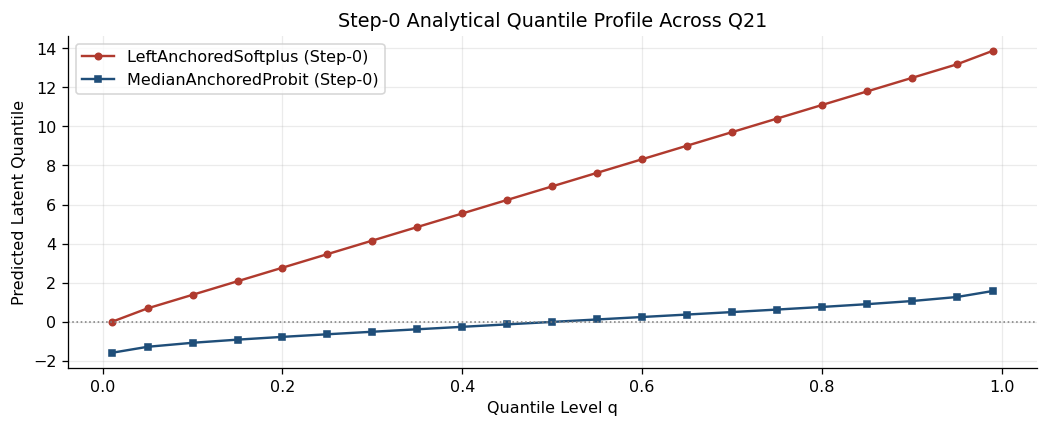

In [4]:
cfg_soft = TSFMConfig.from_yaml(REPO_ROOT / "configs" / "run2_missingness_suffix_cpm.yaml")
cfg_prob = TSFMConfig.from_yaml(REPO_ROOT / "configs" / "run3_probit_localscale_lags.yaml")
m_soft = TSFMModel(cfg_soft).eval()
m_prob = TSFMModel(cfg_prob).eval()

# Synthesize standard Gaussian draws in data space and map to arcsinh latent targets.
y_std = torch.randn(1, 1, 4096)
z_tgt = torch.asinh(y_std)
x_dummy_soft = torch.zeros(1, 1, 128, 32, cfg_soft.c_in)
x_dummy_prob = torch.zeros(1, 1, 128, 32, cfg_prob.c_in)
mask = torch.ones((1, 1, 4096), dtype=torch.bool)
rel128 = torch.arange(-95, 33, dtype=torch.long).view(1, 1, 128)
seg128 = torch.zeros((1, 1, 128), dtype=torch.long)
obs128 = torch.ones((1, 1, 128), dtype=torch.bool)
gid128 = torch.zeros((1, 1, 128), dtype=torch.long)
icov128 = torch.zeros((1, 1, 128), dtype=torch.bool)
sid = torch.zeros((1, 1, 4096), dtype=torch.long)
gtc = torch.ones((1, 1, 4096))

with torch.no_grad():
    q_soft = m_soft(x_dummy_soft, rel128, seg128, obs128, gid128, icov128)
    q_prob = m_prob(x_dummy_prob, rel128, seg128, obs128, gid128, icov128)
    ls_soft = compute_pinball_crps_loss(q_soft, z_tgt, mask, sid, gtc, cfg_soft)
    ls_prob = compute_pinball_crps_loss(q_prob, z_tgt, mask, sid, gtc, cfg_prob)

print(
    f"Step-0 LeftAnchoredSoftplus : CRPS={float(ls_soft.raw_crps):.4f}, Cov80={float(ls_soft.cov80):.3f}, Crossings={float(ls_soft.crossing_rate):.1f}\n"
    f"Step-0 MedianAnchoredProbit : CRPS={float(ls_prob.raw_crps):.4f}, Cov80={float(ls_prob.cov80):.3f}, Crossings={float(ls_prob.crossing_rate):.1f}"
)

fig, ax = plt.subplots(figsize=(9.0, 3.6), constrained_layout=True)
qs = np.array(cfg_prob.quantiles)
ax.plot(qs, q_soft[0, 0, 0].numpy(), "o-", ms=4, label="LeftAnchoredSoftplus (Step-0)", color="#b03a2e")
ax.plot(qs, q_prob[0, 0, 0].numpy(), "s-", ms=4, label="MedianAnchoredProbit (Step-0)", color="#1f4e79")
ax.axhline(0.0, color="gray", ls=":", lw=1.0)
ax.set_xlabel("Quantile Level q")
ax.set_ylabel("Predicted Latent Quantile")
ax.set_title("Step-0 Analytical Quantile Profile Across Q21")
ax.legend()
plt.show()

## 4. `GroupAttention` Safety Invariants

In `Run 4` and `Run 5`, `GroupAttention` is inserted at layers `(3, 7)` and satisfies four invariants tested below on the **post-SGD woken** model (so `head.fc2`, `out_proj`, and `qkv_proj` are all non-zero and actively routing cross-variate signal):
1. Zero-initialized `out_proj.weight` receives nonzero gradients at Step 2 once zero-init `head.fc2` wakes at Step 1, and `qkv_proj.weight` wakes at Step 3 (gated after the `15%` adapter warmup freeze in `scripts/train.py`).
2. `eye_r` diagonal fallback keeps all-masked rows finite inside attention softmax, and `has_group_peer.to(dtype)` forces univariate rows (`0` peers) to receive `0.0` residual update (`iso_diff == 0.0`) even after training `GroupAttention`, while `Group 0` observed context covariates produce strictly non-zero target shifts (`grp0_peer_diff > 1e-4`).
3. Past covariates can inform targets but never attend to targets (`~(icov_q & ~icov_k)`).
4. At horizon columns (`rel_patch_idx > 0`), masked covariate slots (`patch_obs_any == False & icov == True`) cannot pollute targets (`key_ok = obs | (is_hor & ~icov)`). On the 2D heatmaps below, the `G1 UnivTgt` diagonal cell `SELF (x0)` shows `eye_r` softmax safety before `has_group_peer == 0` zeros its residual output.

Step-2 Block-3 GroupAttention out_proj.weight gradient norm        : 6.3395e+00
Step-3 Block-3 GroupAttention qkv_proj.weight gradient norm        : 9.3593e+00
Post-SGD isolated univariate row diff under +100 Group 0 perturb   : 0.0e+00
Post-SGD Group 0 target horizon diff under +50 observed ctx cov    : 3.7270e-03
One-way firewall (covariate diff under +100 target perturbation)   : 0.0e+00
Horizon covariate guard (target diff under +50 unobserved hor cov) : 0.0e+00


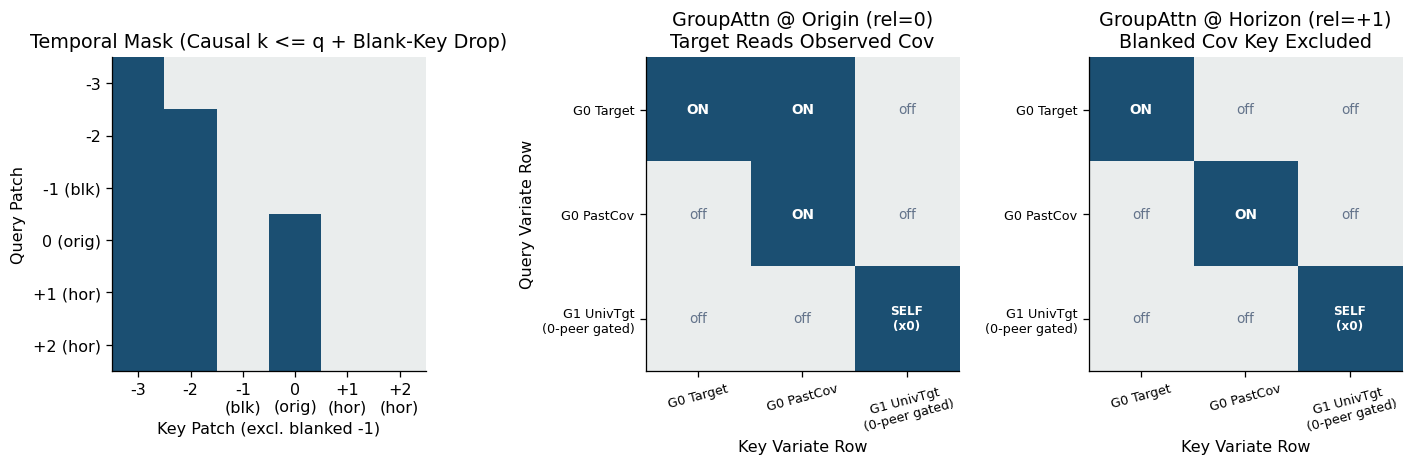

In [5]:
cfg4 = TSFMConfig.from_yaml(REPO_ROOT / "configs" / "run4_multivariate_group_attn.yaml")

pi_mv = torch.randn(1, 3, 6, 32, cfg4.c_in)
rel_mv = torch.arange(-3, 3, dtype=torch.long).view(1, 1, 6).expand(1, 3, 6)
seg_mv = torch.arange(3, dtype=torch.long).view(1, 3, 1).expand(1, 3, 6)
obs_mv = torch.zeros((1, 3, 6), dtype=torch.bool)
obs_mv[:, :, :4] = True  # patches -3..0 observed; +1..+2 horizon

# Case A: Group 0 has row 0 (target) & row 1 (past_cov); Group 1 has row 2 (isolated univariate target).
gid_a = torch.tensor([[0, 0, 1]], dtype=torch.long).unsqueeze(-1).expand(1, 3, 6)
icov_a = torch.tensor([[False, True, False]], dtype=torch.bool).unsqueeze(-1).expand(1, 3, 6)

# Perturb Group 0 row 0 strongly (must leave isolated univariate row 2 at 0.0 even after SGD wake-up).
pi_mv_b = pi_mv.clone()
pi_mv_b[:, 0, :, :, :] += 100.0

# Step-1 updates zero-init head fc2; Step-2 wakes GroupAttention out_proj.weight; Step-3 wakes qkv_proj.weight.
# Non-zero target (-2.0) breaks probit median gradient symmetry so all head and GroupAttention weights wake cleanly.
m_grp = TSFMModel(cfg4)
opt_ga = torch.optim.SGD(m_grp.parameters(), lr=0.2)
m_grp.train()
for s_i in range(3):
    opt_ga.zero_grad(set_to_none=True)
    p_s = m_grp(pi_mv, rel_mv, seg_mv, obs_mv, gid_a, icov_a)
    (p_s[:, 0, 4 * 32 :, :] - 2.0).pow(2).mean().backward()
    if s_i == 1:
        ga_out_grad = float(m_grp.blocks[3].group_attn.out_proj.weight.grad.norm().item())
    if s_i == 2:
        ga_qkv_grad = float(m_grp.blocks[3].group_attn.qkv_proj.weight.grad.norm().item())
    opt_ga.step()

# Verify woken post-SGD invariants in CPU float32:
# univariate row 2 == 0.0, Group 0 obs cov sensitivity > 1e-4, one-way firewall == 0.0, horizon cov guard == 0.0.
m_grp.eval()
ga_blk = m_grp.blocks[3].group_attn
h_test = torch.randn(1, 3, 6, cfg4.d_model)
h_test_pert = h_test.clone()
h_test_pert[:, 0] += 100.0
with torch.no_grad():
    out_woken = m_grp(pi_mv, rel_mv, seg_mv, obs_mv, gid_a, icov_a)
    out_woken_b = m_grp(pi_mv_b, rel_mv, seg_mv, obs_mv, gid_a, icov_a)
    iso_diff = float((out_woken[:, 2] - out_woken_b[:, 2]).abs().max())

    pi_ctx_cov = pi_mv.clone()
    pi_ctx_cov[:, 1, :4, :, :] += 50.0
    out_ctx_cov = m_grp(pi_ctx_cov, rel_mv, seg_mv, obs_mv, gid_a, icov_a)
    grp0_peer_diff = float((out_woken[:, 0, 4 * 32 :, :] - out_ctx_cov[:, 0, 4 * 32 :, :]).abs().max())

    cov_diff = float((ga_blk(h_test, gid_a, icov_a)[:, 1] - ga_blk(h_test_pert, gid_a, icov_a)[:, 1]).abs().max())
    pi_hor_cov = pi_mv.clone()
    pi_hor_cov[:, 1, 4:, :, :] += 50.0  # Unobserved horizon covariate slots must be excluded from keys
    out_hor_cov = m_grp(pi_hor_cov, rel_mv, seg_mv, obs_mv, gid_a, icov_a)
    hor_cov_leak = float((out_woken[:, 0, 4 * 32 :] - out_hor_cov[:, 0, 4 * 32 :]).abs().max())

assert ga_out_grad > 0.0 and ga_qkv_grad > 0.0
assert iso_diff == 0.0 and grp0_peer_diff > 1e-4
assert cov_diff == 0.0 and hor_cov_leak == 0.0

print(f"Step-2 Block-3 GroupAttention out_proj.weight gradient norm        : {ga_out_grad:.4e}")
print(f"Step-3 Block-3 GroupAttention qkv_proj.weight gradient norm        : {ga_qkv_grad:.4e}")
print(f"Post-SGD isolated univariate row diff under +100 Group 0 perturb   : {iso_diff:.1e}")
print(f"Post-SGD Group 0 target horizon diff under +50 observed ctx cov    : {grp0_peer_diff:.4e}")
print(f"One-way firewall (covariate diff under +100 target perturbation)   : {cov_diff:.1e}")
print(f"Horizon covariate guard (target diff under +50 unobserved hor cov) : {hor_cov_leak:.1e}")

# 2D Attention-Mask Heatmap: Temporal (with blanked ctx patch -1) vs GroupAttention (Origin vs Horizon+1).
from matplotlib.colors import ListedColormap

obs_demo = torch.tensor([[[True, True, False, True, False, False]]], dtype=torch.bool)
rel_demo = torch.tensor([[[-3, -2, -1, 0, 1, 2]]], dtype=torch.long)
seg_demo = torch.zeros((1, 1, 6), dtype=torch.long)
tmask_demo = build_temporal_mask(seg_demo, rel_demo, obs_demo, exclude_blank_keys=True)[0, 0].numpy()


def _compute_group_mask_col(gid_row: torch.Tensor, icov_row: torch.Tensor, obs_row: torch.Tensor, is_hor_col: bool) -> np.ndarray:
    same_grp = (gid_row[:, None] == gid_row[None, :]) & (gid_row[:, None] >= 0)
    firewall = ~(icov_row[:, None] & (~icov_row[None, :]))
    key_ok = (obs_row | ((~icov_row) if is_hor_col else torch.zeros_like(icov_row)))[None, :]
    eye = torch.eye(gid_row.size(0), dtype=torch.bool)
    return ((same_grp & firewall & key_ok) | eye).numpy()


gmask_orig = _compute_group_mask_col(gid_a[0, :, 3], icov_a[0, :, 3], obs_mv[0, :, 3], is_hor_col=False)
gmask_hor1 = _compute_group_mask_col(gid_a[0, :, 4], icov_a[0, :, 4], obs_mv[0, :, 4], is_hor_col=True)

fig_m, axes_m = plt.subplots(1, 3, figsize=(12.4, 3.8), gridspec_kw={"width_ratios": [1.42, 1.0, 1.0]}, constrained_layout=True)
mask_cmap = ListedColormap(["#EAEDED", "#1B4F72"])

axes_m[0].imshow(tmask_demo.astype(int), cmap=mask_cmap, vmin=0, vmax=1)
axes_m[0].grid(False)
tx_labels = ["-3", "-2", "-1\n(blk)", "0\n(orig)", "+1\n(hor)", "+2\n(hor)"]
ty_labels = ["-3", "-2", "-1 (blk)", "0 (orig)", "+1 (hor)", "+2 (hor)"]
axes_m[0].set_xticks(range(6), tx_labels)
axes_m[0].set_yticks(range(6), ty_labels)
axes_m[0].set_xlabel("Key Patch (excl. blanked -1)")
axes_m[0].set_ylabel("Query Patch")
axes_m[0].set_title("Temporal Mask (Causal k <= q + Blank-Key Drop)")

g_labels = ["G0 Target", "G0 PastCov", "G1 UnivTgt\n(0-peer gated)"]
for idx_g, (ax_g, mat, title) in enumerate((
    (axes_m[1], gmask_orig, "GroupAttn @ Origin (rel=0)\nTarget Reads Observed Cov"),
    (axes_m[2], gmask_hor1, "GroupAttn @ Horizon (rel=+1)\nBlanked Cov Key Excluded"),
)):
    ax_g.imshow(mat.astype(int), cmap=mask_cmap, vmin=0, vmax=1)
    ax_g.grid(False)
    ax_g.set_xticks(range(3), g_labels, rotation=15, fontsize=8.0)
    ax_g.set_yticks(range(3), g_labels, fontsize=8.0)
    if idx_g == 0:
        ax_g.set_ylabel("Query Variate Row")
    ax_g.set_xlabel("Key Variate Row")
    ax_g.set_title(title)
    for qi in range(3):
        for ki in range(3):
            if qi == 2 and ki == 2:
                txt, fs = "SELF\n(x0)", 7.5
            else:
                txt, fs = ("ON" if mat[qi, ki] else "off"), 8.5
            ax_g.text(
                ki,
                qi,
                txt,
                ha="center",
                va="center",
                fontsize=fs,
                fontweight="bold" if mat[qi, ki] else "normal",
                color="white" if mat[qi, ki] else "#64748B",
            )
plt.show()

## 5. Single-Batch Convergence & Strict Zero-Crossing Verification (`60` Steps)

Using genuine `build_group_patch_features(...)` tensors (observed sinusoidal targets + coupled covariate in context patches `-5..0`, strictly zeroed raw signal channel `ch 0` in horizon patches `+1..+2`), `TSFMModel` drives `2x` pinball CRPS cleanly down with `0.0` quantile crossings.

Single-batch CRPS: step 1 = 0.4675 -> step 60 = 0.0190 (95.9% reduction), max crossing = 0.0


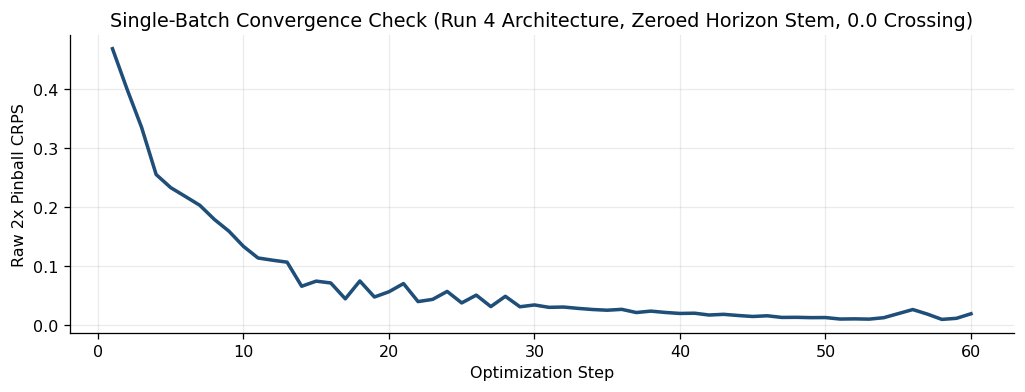

In [6]:
cfg_overfit = TSFMConfig.from_yaml(REPO_ROOT / "configs" / "run4_multivariate_group_attn.yaml")
m_overfit = TSFMModel(cfg_overfit)
opt = torch.optim.AdamW(m_overfit.parameters(), lr=8e-4, weight_decay=0.0)

# Build real context vs zeroed-horizon stem features for 2 target series + 2 past covariates (T_ctx=192 -> 6 ctx patches, H=64 -> 2 hor patches).
t_full = np.arange(256, dtype=np.float32)
cov0 = np.sin(2.0 * np.pi * t_full / 48.0)
cov1 = np.cos(2.0 * np.pi * t_full / 24.0)
tgt0 = 0.8 * cov0 + 0.4 * cov1
tgt1 = -0.6 * cov0 + 0.5 * cov1
full_raw = np.stack([tgt0, tgt1, cov0, cov1], axis=0)  # [4, 256]

pi_rows, obs_rows, norms_gt = [], [], []
for r_idx in range(4):
    p_r, o_r, mu_r, sig_r = build_group_patch_features(
        y_ctx_real=full_raw[r_idx : r_idx + 1, :192],
        left_pad=0,
        n_ctx_patches=6,
        n_hor_patches=2,
        patch_size=cfg_overfit.patch_size,
        scaling_mode=cfg_overfit.scaling_mode,
        use_local_scale_and_lags=cfg_overfit.use_local_scale_and_lags,
    )
    pi_rows.append(p_r[0])
    obs_rows.append(o_r[0])
    norms_gt.append(np.arcsinh((full_raw[r_idx] - mu_r[0]) / max(sig_r[0], 1e-6)))

b_pi = torch.from_numpy(np.stack(pi_rows, axis=0)).unsqueeze(0)  # [1, 4, 8, 32, 17]
b_obs = torch.from_numpy(np.stack(obs_rows, axis=0)).unsqueeze(0)
assert float(b_pi[0, :, 6:, :, 0].abs().max()) == 0.0, "Horizon raw target channel must be strictly zero!"
b_rel = torch.arange(-5, 3, dtype=torch.long).view(1, 1, 8).expand(1, 4, 8)
b_seg = torch.arange(4, dtype=torch.long).view(1, 4, 1).expand(1, 4, 8)
b_gid = torch.zeros((1, 4, 8), dtype=torch.long)
b_icov = torch.tensor([[False, False, True, True]]).unsqueeze(-1).expand(1, 4, 8)
b_tgt = torch.from_numpy(np.stack(norms_gt, axis=0)).unsqueeze(0)  # [1, 4, 256]
b_lmask = torch.zeros((1, 4, 256), dtype=torch.bool)
b_lmask[:, :2, 6 * 32 :] = True
b_sid = torch.arange(4, dtype=torch.long).view(1, 4, 1).expand(1, 4, 256)
b_gtc = torch.full((1, 4, 256), 2.0)

crps_hist, cross_hist = [], []
for step in range(1, 61):
    opt.zero_grad(set_to_none=True)
    pq = m_overfit(b_pi, b_rel, b_seg, b_obs, b_gid, b_icov)
    lm = compute_pinball_crps_loss(pq, b_tgt, b_lmask, b_sid, b_gtc, cfg_overfit)
    lm.loss.backward()
    opt.step()
    crps_hist.append(float(lm.raw_crps))
    cross_hist.append(float(lm.crossing_rate))

print(
    f"Single-batch CRPS: step 1 = {crps_hist[0]:.4f} -> step 60 = {crps_hist[-1]:.4f} "
    f"({(1.0 - crps_hist[-1]/crps_hist[0])*100:.1f}% reduction), max crossing = {max(cross_hist):.1f}"
)

fig, ax = plt.subplots(figsize=(8.8, 3.3), constrained_layout=True)
ax.plot(np.arange(1, 61), crps_hist, lw=2.2, color="#1f4e79")
ax.set_xlabel("Optimization Step")
ax.set_ylabel("Raw 2x Pinball CRPS")
ax.set_title("Single-Batch Convergence Check (Run 4 Architecture, Zeroed Horizon Stem, 0.0 Crossing)")
plt.show()

## Summary
- All `6` progressive configurations instantiate cleanly (`14.82M -> 15.14M -> 16.32M` parameters) and enforce strict future-blind causal masking, `eye_l` all-`NaN` finiteness, and `rel_origin_pos` short-series horizon disambiguation.
- `MedianAnchoredProbitHead` calibrates Step-0 empirical `Cov80` to `~80%` (`~10x` lower initial CRPS vs. left-anchored softplus) with structural `q01 <= ... <= q99` (`Q21`) monotonicity.
- `GroupAttention` preserves exact univariate invariance (`0.0` diff), enforces one-way covariate-to-target information flow, excludes unobserved horizon covariate slots, and converges smoothly without quantile crossings.